<center><h1>Mutyala_Yogita_HW4</h1></center>
<br>
<br>

Name: Yogita Mutyala
<br>
Github Username: YogitaMutyala
<br>
USC ID: 4421997071

##  1 Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

###  (a) Obtain Data

Import packages

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
import statsmodels.api as sm
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, roc_auc_score,accuracy_score, confusion_matrix
from sklearn.base import clone
from scipy.special import expit
from sklearn.naive_bayes import GaussianNB, MultinomialNB

Get the AReM Data Set

In [2]:
data_path = Path("../data/AReM")
activities = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]

###  (b) Splitting Data

In [3]:
train_files=[]
test_files = []
for activity in activities:
    for file in sorted((data_path / activity).glob("dataset*.csv")):
        number = int(file.stem.replace("dataset", ""))
        test_numbers = [1, 2] if activity.startswith("bending") else [1, 2, 3]
        (test_files if number in test_numbers else train_files).append((activity, file))
print("Instances for Training are",len(train_files),"and for Testing are",len(test_files))

Instances for Training are 69 and for Testing are 19


###  (c) Feature Extraction

Common time-domain features for time series classification:
- Location: minimum, maximum, mean, median, first/third quartile, mode
- Spread: standard deviation, variance, range, interquartile range (IQR)
- Shape: skewness, kurtosis
- Energy/amplitude: root mean square (RMS), sum of squares, peak-to-peak amplitude
- Dynamics: number of zero/mean crossings, mean absolute change (first differences), autocorrelation at selected lags, slope of a linear trend

In [4]:
columns = ["time", "avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]
def read_file(file):
    # handle file using spaces and not commas
    separator = r"\s+" if file.parent.name == "bending2" and file.stem == "dataset4" else ","
    return pd.read_csv(file, comment="#", header=None, names=columns, sep=separator, usecols=range(7), engine="python")
def extract_features(file):
    features = {}
    for number, column in enumerate(columns[1:], 1):
        values = read_file(file)[column]
        features.update({
            f"min{number}": values.min(),
            f"max{number}": values.max(),
            f"mean{number}": values.mean(),
            f"median{number}": values.median(),
            f"std{number}": values.std(),
            f"1st_quart{number}": values.quantile(0.25),
            f"3rd_quart{number}": values.quantile(0.75)
        })
    return features
rows = [ {"activity": activity, "dataset": file.stem, "split": split, **extract_features(file)}
    for split, files in [("train", train_files), ("test", test_files)]
    for activity, file in files]
features_df = pd.DataFrame(rows)
print("Number of instances are", len(features_df))
print("Number of extracted features:", features_df.shape[1] - 3)
features_df

Number of instances are 88
Number of extracted features: 42


,activity,dataset,split,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
0,bending1,dataset3,train,35.00,47.40,43.954500,44.330,1.558835,43.00,45.0000,...,1.999604,35.3625,36.500,0.0,1.79,0.493292,0.430,0.513506,0.000,0.940
1,bending1,dataset4,train,33.00,47.75,42.179812,43.500,3.670666,39.15,45.0000,...,3.849448,30.4575,36.330,0.0,2.18,0.613521,0.500,0.524317,0.000,1.000
2,bending1,dataset5,train,33.00,45.75,41.678063,41.750,2.243490,41.33,42.7500,...,2.411026,28.4575,31.250,0.0,1.79,0.383292,0.430,0.389164,0.000,0.500
3,bending1,dataset6,train,37.00,48.00,43.454958,43.250,1.386098,42.50,45.0000,...,2.488862,22.2500,24.000,0.0,5.26,0.679646,0.500,0.622534,0.430,0.870
4,bending1,dataset7,train,36.25,48.00,43.969125,44.500,1.618364,43.31,44.6700,...,3.318301,20.5000,23.750,0.0,2.96,0.555312,0.490,0.487826,0.000,0.830
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,standing,dataset2,test,35.50,46.25,43.174938,43.670,1.989052,42.50,44.5000,...,2.983976,12.7500,16.500,0.0,5.72,0.911979,0.830,0.666161,0.470,1.220
84,standing,dataset3,test,32.75,47.00,42.760562,44.500,3.398919,41.33,45.3725,...,4.296574,13.0000,18.565,0.0,5.73,0.842271,0.710,0.722165,0.430,1.090
85,walking,dataset1,test,19.33,43.50,34.227771,35.500,4.889576,30.50,37.7500,...,3.092094,14.7500,18.670,0.0,9.74,3.394125,3.100,1.792090,2.105,4.425
86,walking,dataset2,test,12.50,45.00,33.509729,34.125,4.850923,30.50,36.7500,...,3.133564,14.6275,18.750,0.0,8.96,3.378479,3.085,1.787360,2.060,4.440


I selected min, mean, and max of each series. Together they capture the location and range
of the signal and are less redundant than median/quartiles, which are highly correlated with
the mean.

## 2.  Time Series Classification Part 2: Binary and Multiclass Classification

###    (a) Binary Classification Using Logistic Regression

####   i. Plots

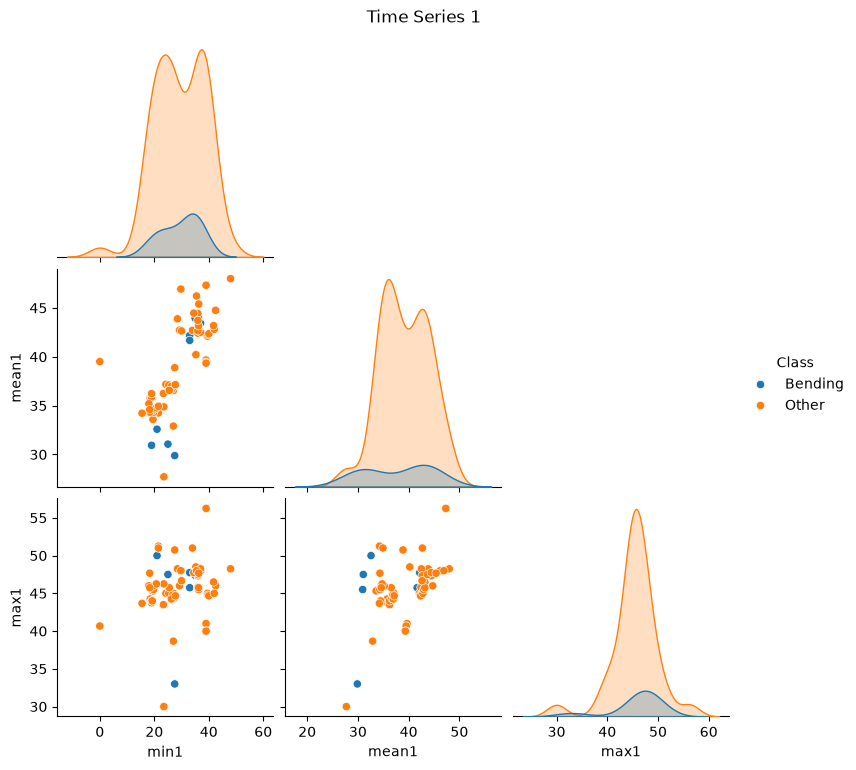

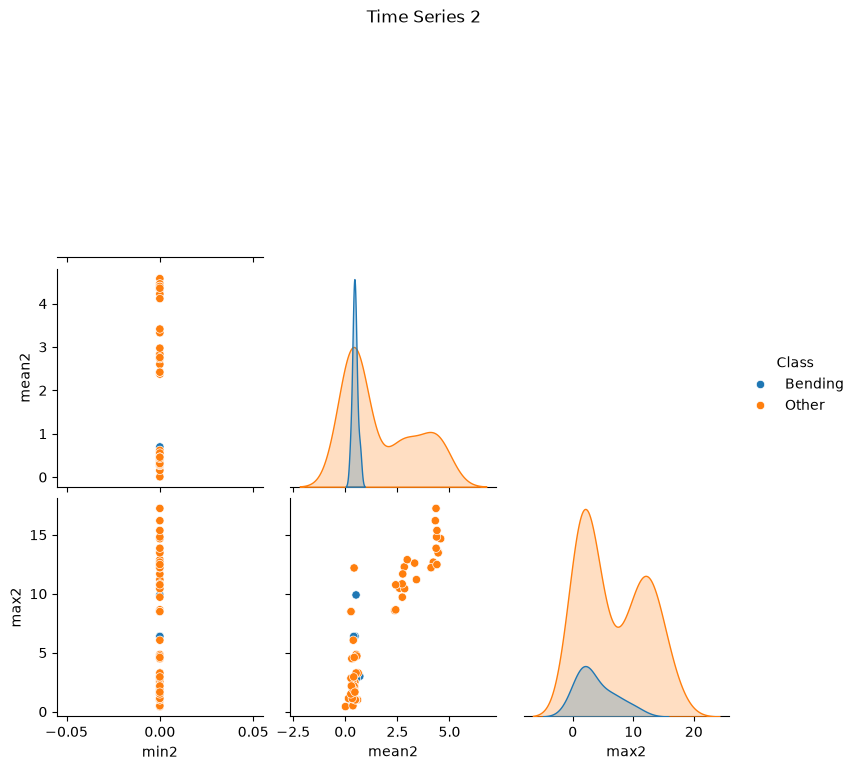

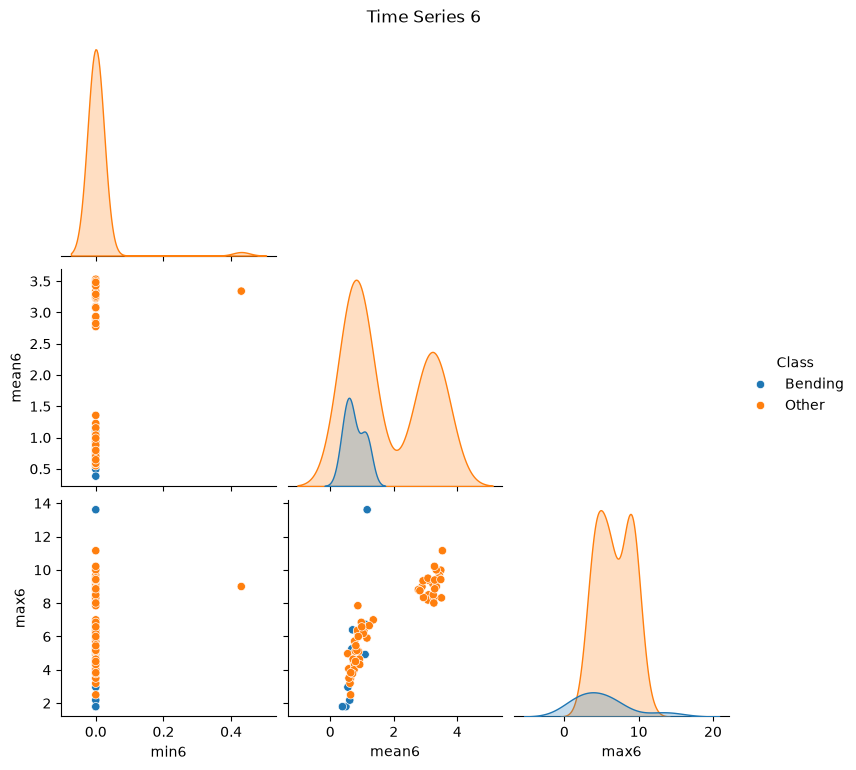

In [5]:
plot_rows = []
for activity, file in train_files:
    data = read_file(file)
    row = {"Class": "Bending" if activity.startswith("bending") else "Other"}
    for series, column in enumerate(columns[1:], 1):
        row[f"min{series}"] = data[column].min()
        row[f"mean{series}"] = data[column].mean()
        row[f"max{series}"] = data[column].max()
    plot_rows.append(row)
plot_data = pd.DataFrame(plot_rows)
for series in [1, 2, 6]:
    sns.pairplot(
        plot_data,
        vars=[f"min{series}", f"mean{series}", f"max{series}"],
        hue="Class",
        corner=True)
    plt.suptitle(f"Time Series {series}", y=1.02)
    plt.show()

Understanding:
In comparison, time series 1 has clear separation between bending and other activities using minimum and maximum. Time series 2 and 6 show more overlap so their features are less effective individually. I think combining features from multiple time series could improve classification.

####   ii. Splitted Plots

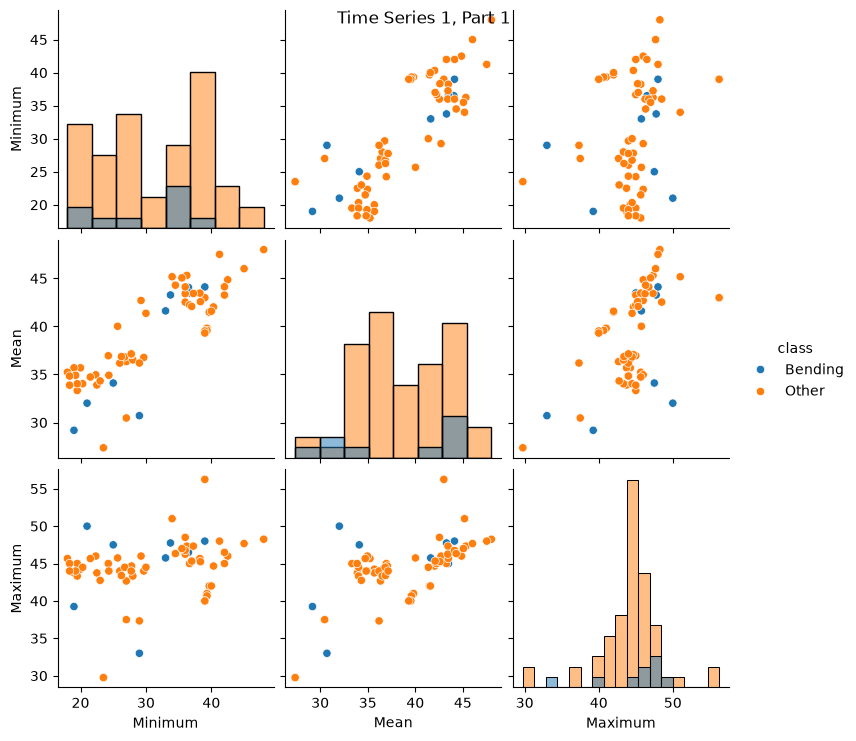

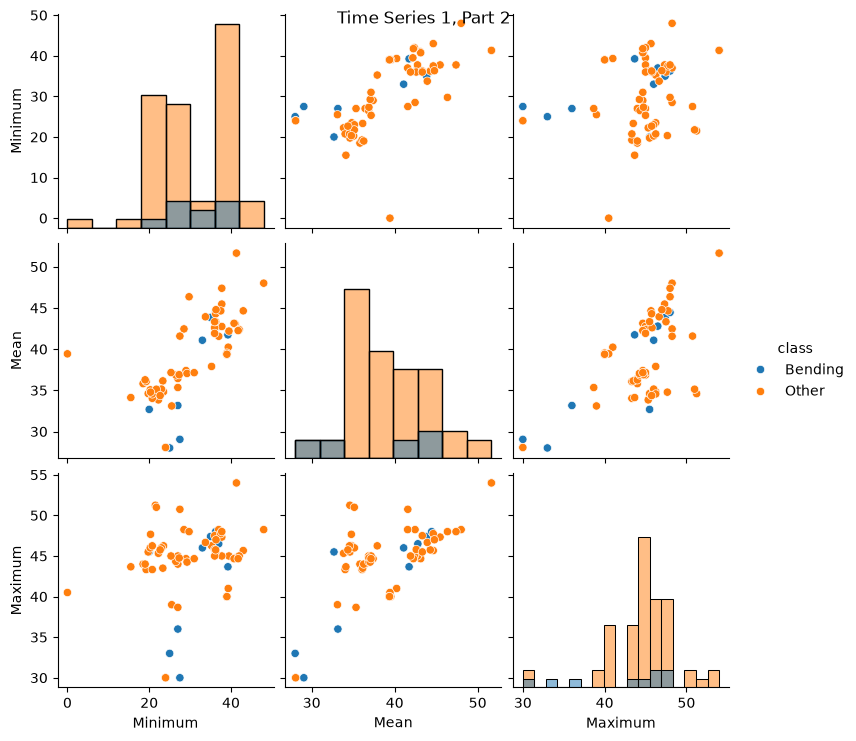

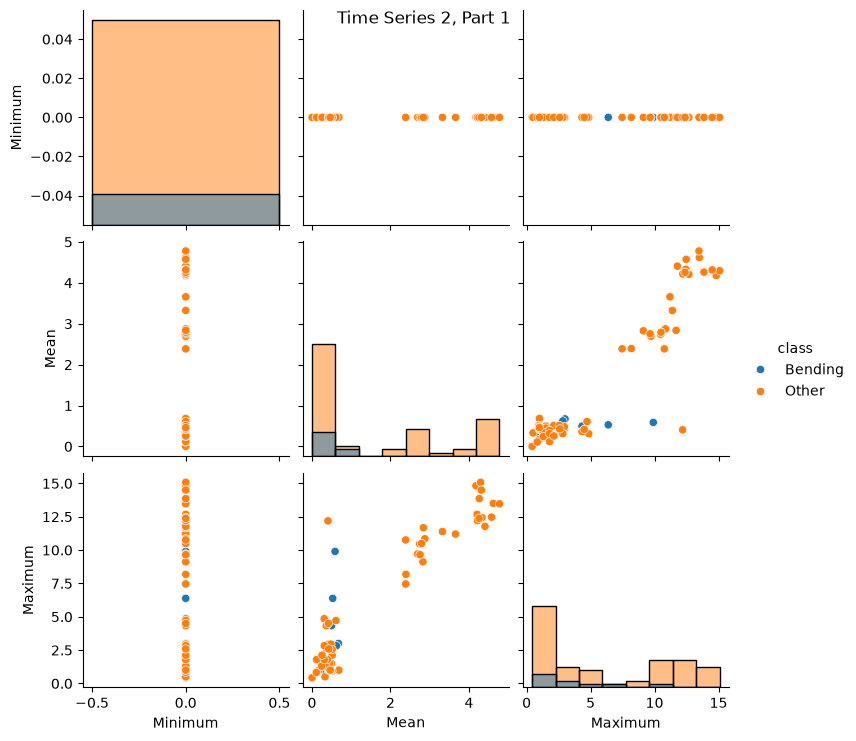

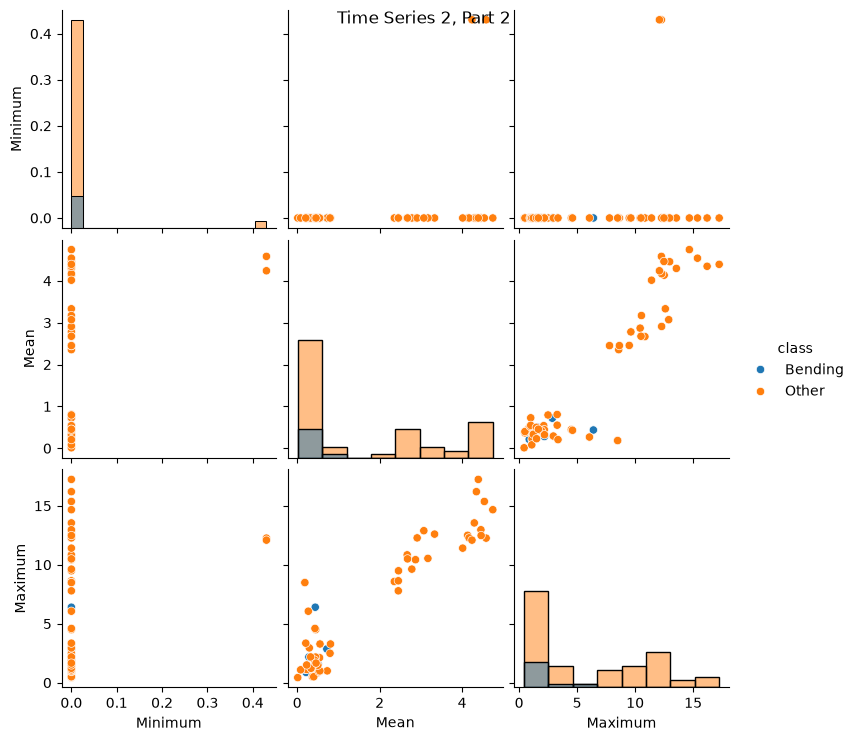

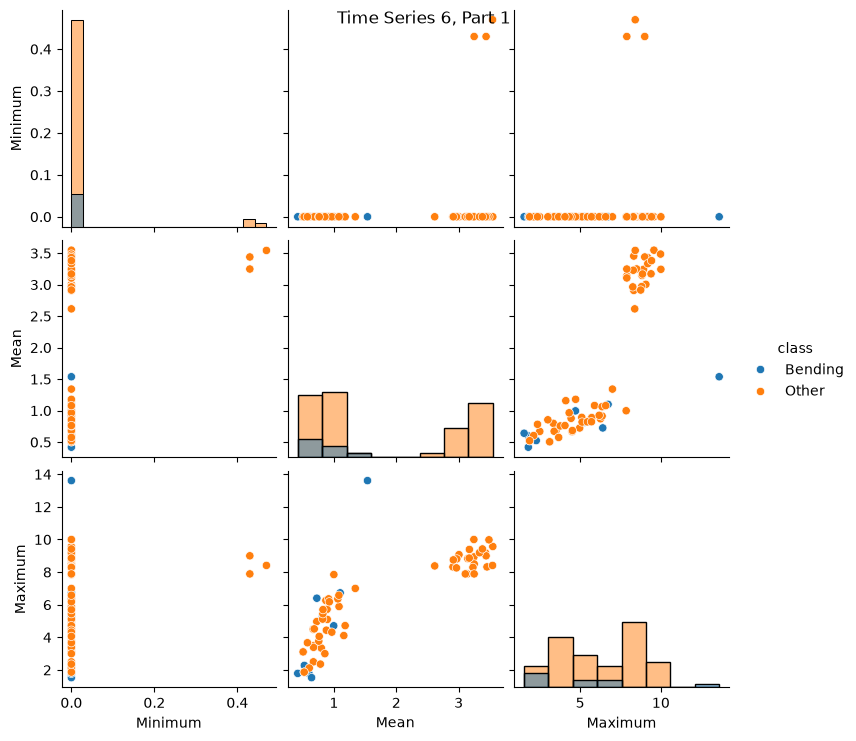

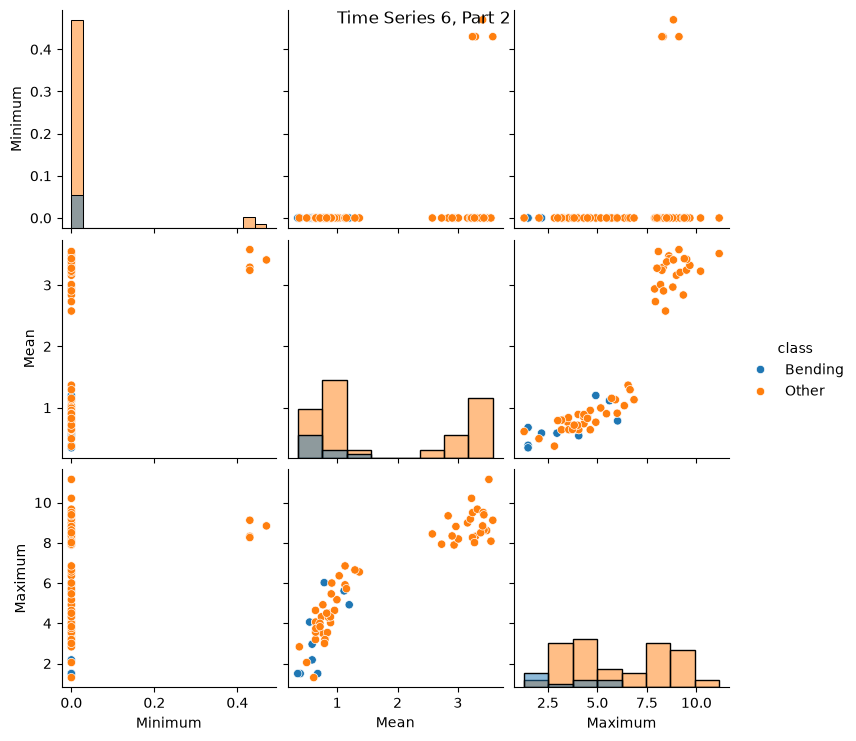

In [6]:
# extract feature post splitting
def extractf(file, l):
    data, features = read_file(file), {}
    # Split row numbers so each segment remains a DataFrame
    for part, rows in enumerate(np.array_split(np.arange(len(data)), l), 1):
        segment = data.iloc[rows]
        for series, column in enumerate(columns[1:], 1):
            values = segment[column]
            features.update({
                f"min{series}_part{part}": values.min(),
                f"mean{series}_part{part}": values.mean(),
                f"max{series}_part{part}": values.max()
            })
    return features
# split train
two_part_train = pd.DataFrame([{"class": "Bending" if activity.startswith("bending") else "Other",**extractf(file, 2)}
    for activity, file in train_files ])
for series in [1, 2, 6]:
    for part in [1, 2]:
        selected = [f"{feature}{series}_part{part}" for feature in ["min", "mean", "max"]]
        plot_data = two_part_train[selected + ["class"]].rename(columns=dict(zip(selected, ["Minimum", "Mean", "Maximum"])))
        graph = sns.pairplot(plot_data,vars=["Minimum", "Mean", "Maximum"],hue="class",diag_kind="hist")
        graph.fig.suptitle(f"Time Series {series}, Part {part}")
        plt.show()

Understanding:

Splitting the time series provided more in-detailed information but it does not improve class separation that much. The minimum features provide little information because most of values are zero.

####   iii. Time Series Segments

In [7]:
# get features from l parts
def partlf(file, l):
    data, features = read_file(file), {}
    for part, rows in enumerate(np.array_split(np.arange(len(data)), l), 1):
        segment = data.iloc[rows]
        for series, column in enumerate(columns[1:], 1):
            x = segment[column]
            values = [x.min(), x.max(), x.mean(), x.median(), x.std(), x.quantile(.25), x.quantile(.75)]
            for name, value in zip(["min", "max", "mean", "median", "std", "q1", "q3"], values):features[f"{name}{series}_part{part}"] = value
    return features
y_train = np.array([ 1 if activity.startswith("bending") else 0 for activity, file in train_files ])
cv = StratifiedKFold(5, shuffle=True, random_state=42)
base_model = LogisticRegression(C=1e6, solver="liblinear", max_iter=2000)
results, models = [], {}
for l in range(1, 21):
    # for monitoring
    print(f"Testing l = {l}")
    X = pd.DataFrame([partlf(file, l) for activity, file in train_files])
    model = Pipeline([ ("scale", StandardScaler()), ("rfe", RFE(base_model, step=0.1)), ("logistic", base_model)])
    p_values = range(1, min(21, X.shape[1] + 1))
    search = GridSearchCV( model, {"rfe__n_features_to_select": p_values}, cv=cv, scoring="accuracy",n_jobs=-1).fit(X, y_train)
    results.append([l, search.best_params_["rfe__n_features_to_select"], search.best_score_])
    models[l] = (search, X)
cv_results = pd.DataFrame( results, columns=["l", "p", "CV Accuracy"] )
best = cv_results.loc[cv_results["CV Accuracy"].idxmax()]
best_l, best_p = int(best["l"]), int(best["p"])
print(cv_results)
print("The Best l is", best_l,"p is", best_p, f"and CV accuracy is {best['CV Accuracy']:.4f}")

Testing l = 1
Testing l = 2
Testing l = 3
Testing l = 4
Testing l = 5
Testing l = 6
Testing l = 7
Testing l = 8
Testing l = 9
Testing l = 10
Testing l = 11
Testing l = 12
Testing l = 13
Testing l = 14
Testing l = 15
Testing l = 16
Testing l = 17
Testing l = 18
Testing l = 19
Testing l = 20
     l   p  CV Accuracy
0    1   3     0.985714
1    2   7     0.957143
2    3   6     0.971429
3    4  11     0.957143
4    5   2     0.957143
5    6   2     0.957143
6    7  16     0.971429
7    8   9     0.942857
8    9  10     0.941758
9   10  18     0.957143
10  11   6     0.971429
11  12   2     0.985714
12  13  11     0.914286
13  14  19     0.942857
14  15  18     0.928571
15  16  10     0.956044
16  17  12     0.942857
17  18  20     0.928571
18  19  15     0.971429
19  20  19     0.971429
The Best l is 1 p is 3 and CV accuracy is 0.9857


Understanding:

Among the evaluated values of p=1,2,3,...,20, best pair here is (l, p) = (1, 3) with cross-validation accuracy of 98.57%. Although (12, 2) produced the same accuracy (1, 3) was selected because it is the simpler model and does not need splitting each time series.

The correct approach performs scaling and RFE separately within each training fold by placing them inside the pipeline.
It would be wrong to perform scaling or feature selection on the complete training set before cross-validation 
Stratified cross-validation is used so that each fold contains approximately the same proportion of bending and non-bending instances.

####   iv. Confusion Matrix

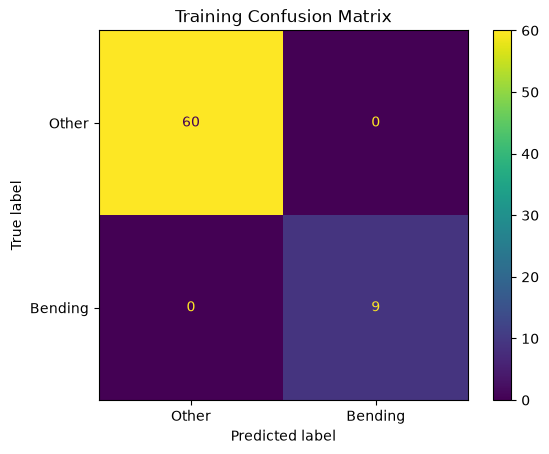

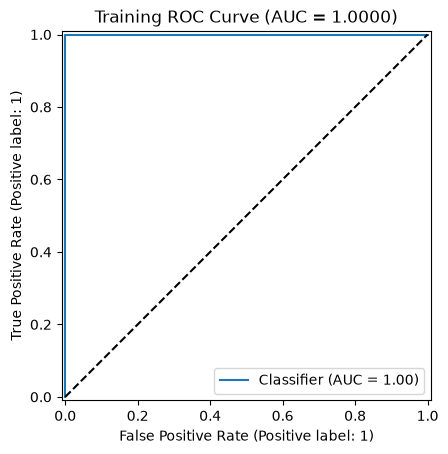

The training AUC is 1.0


,Feature,Coefficient,p-value
0,Intercept,-35.614815,0.781976
1,q31_part1,-10.405556,0.869810
2,min5_part1,17.949229,0.837083
3,max5_part1,22.064774,0.824663


In [8]:
# take best model and train features
bests, X_train_best = models[best_l]
bestm = bests.best_estimator_
train_pred = bestm.predict(X_train_best)
train_prob = bestm.predict_proba(X_train_best)[:, 1]
ConfusionMatrixDisplay.from_predictions( y_train, train_pred, display_labels=["Other", "Bending"],)
plt.title("Training Confusion Matrix")
plt.show()
# ROC AUC
RocCurveDisplay.from_predictions(y_train, train_prob)
plt.plot([0, 1], [0, 1], "k--")
plt.title(f"Training ROC Curve (AUC = {roc_auc_score(y_train, train_prob):.4f})")
plt.show()
# feature slect
scaled_X = bestm["scale"].transform(X_train_best)
selected = bestm["rfe"].support_
selected_names = X_train_best.columns[selected]
selected_X = scaled_X[:, selected]
# fit regression
stat_model = sm.Logit( y_train, sm.add_constant(selected_X) ).fit(method="lbfgs", maxiter=2000, disp=False)
resultsp = pd.DataFrame({ "Feature": ["Intercept"] + selected_names.tolist(),
    "Coefficient": stat_model.params,
    "p-value": stat_model.pvalues})
print("The training AUC is", round(roc_auc_score(y_train, train_prob), 4))
resultsp

Understanding:

The model correctly classified all training instances with AUC of 1.0 shows perfect separation on the training set but the large coefficient estimates and high p-values may suggest that logistic regression parameter estimates are unstable because of this separation

####   v. Test Classifier

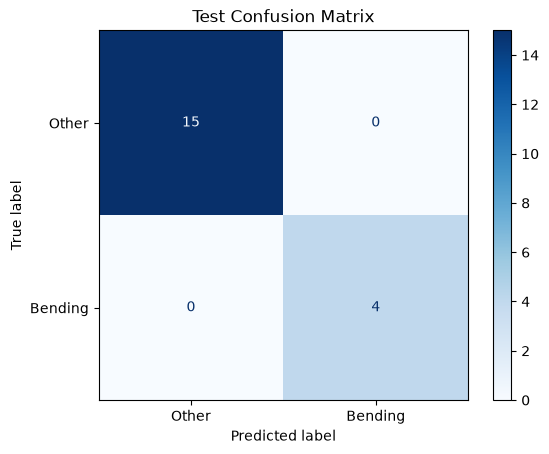

Cross-validation accuracy: 0.9857
Test accuracy: 1.0


In [9]:
# take test features
X_test = pd.DataFrame([ partlf(file, best_l) for activity, file in test_files ])
y_test = np.array([ 1 if activity.startswith("bending") else 0 for activity, file in test_files ])
test_pred = bestm.predict(X_test)
test_accuracy = accuracy_score(y_test, test_pred)
ConfusionMatrixDisplay.from_predictions( y_test, test_pred, display_labels=["Other", "Bending"], cmap="Blues")
plt.title("Test Confusion Matrix")
plt.show()
print("Cross-validation accuracy:", round(best["CV Accuracy"], 4))
print("Test accuracy:", round(test_accuracy, 4))

Understanding: The test accuracy is 100%, which is slightly higher than the cross-validation accuracy of 98.57%. The model generalizes pretty well to  test data. But 100% result should be interpreted carefully as the test set contains only 19 instances

####   vi. Separation

Understanding:

Yes, the classes are well separated. The classifier achieved 100% training accuracy and an AUC of 1.0. The large coefficients and unreliable p-values indicate that this separation caused instability when estimating the logistic regression parameters.

####   vii. Imbalance

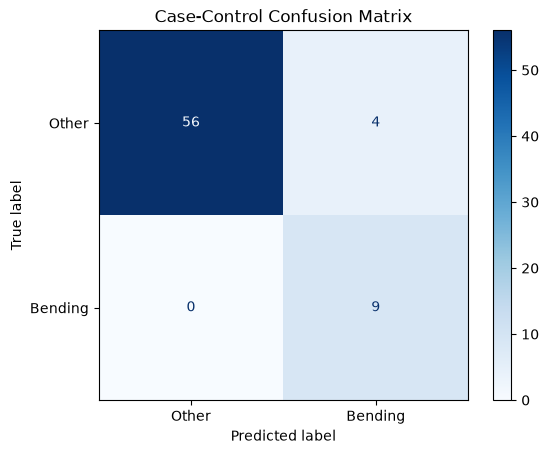

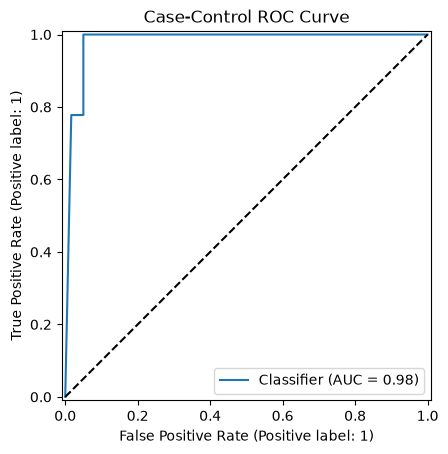

Original class counts: [60  9]
Balanced class counts: [9 9]
Intercept adjustment: -1.8971
AUC: 0.9824
Original intercept: 6.0442
Adjusted intercept: 4.1471


In [10]:
# equal count of bending and other cases
bendingc = np.where(y_train == 1)[0]
otherc = np.where(y_train == 0)[0]
np.random.seed(42)
balanced_index = np.r_[bendingc,np.random.choice(otherc, len(bendingc), replace=False)]
Xb = X_train_best.iloc[balanced_index]
yb = y_train[balanced_index]
# fit
case_control_model = clone(bestm).fit(Xb, yb)
population_rate = y_train.mean()
sample_rate = yb.mean()
adjustment = np.log( (population_rate / (1 - population_rate)) / (sample_rate / (1 - sample_rate)) )
original_intercept = case_control_model["logistic"].intercept_[0]
adjusted_intercept = original_intercept + adjustment
adjusted_log_odds = ( case_control_model.decision_function(X_train_best) + adjustment )
probc = expit(adjusted_log_odds)
corrected_prediction = (probc >= 0.5).astype(int)
ConfusionMatrixDisplay.from_predictions( y_train, corrected_prediction, display_labels=["Other", "Bending"], cmap="Blues")
plt.title("Case-Control Confusion Matrix")
plt.show()
RocCurveDisplay.from_predictions(y_train, probc)
plt.plot([0, 1], [0, 1], "k--")
plt.title("Case-Control ROC Curve")
plt.show()
print("Original class counts:", np.bincount(y_train))
print("Balanced class counts:", np.bincount(yb))
print("Intercept adjustment:", round(adjustment, 4))
print("AUC:", round(roc_auc_score(y_train, probc), 4))
print("Original intercept:", round(original_intercept, 4))
print("Adjusted intercept:", round(adjusted_intercept, 4))

Understanding:

The original training data are imbalanced, with 60 Other instances and 9 Bending instances. The case control sampling created  balanced sample containing 9 observations from each class. After correcting the intercept for the original class proportions the model identified all bending instances but incorrectly classified 4 Other instances. Its AUC of 0.9824 still indicates strong discrimination.

###     (b) Binary Classification Using L1-penalized logistic regression

####  i. Time Series Segments

In [11]:
C_values = [0.01, 0.1, 1, 10, 100]
l1_results, l1_models = [], {}
for l in range(1, 21):
    # monitor
    print(f"Testing l = {l}/20", flush=True)
    X = pd.DataFrame([ partlf(file, l) for activity, file in train_files ])
    model = Pipeline([ ("scale", StandardScaler()), ("logistic", LogisticRegression(l1_ratio=1, solver="liblinear", max_iter=1000, tol=1e-3,random_state=42))])
    search = GridSearchCV( model, {"logistic__C": C_values},  cv=cv, scoring="accuracy",  n_jobs=-1 ).fit(X, y_train)
    l1_results.append([ l, search.best_params_["logistic__C"], search.best_score_ ])
    l1_models[l] = (search, X)
l1_results = pd.DataFrame( l1_results, columns=["l", "C", "CV Accuracy"] )
best_row = l1_results.loc[l1_results["CV Accuracy"].idxmax()]
best_l_l1 = int(best_row["l"])
l1_search, X_train_l1 = l1_models[best_l_l1]
best_l1_model = l1_search.best_estimator_
best_C = l1_search.best_params_["logistic__C"]
# test
Xl1test = pd.DataFrame([ partlf(file, best_l_l1) for activity, file in test_files ])
l1_test_accuracy = accuracy_score( y_test, best_l1_model.predict(Xl1test))
nonzero_features = np.sum( best_l1_model["logistic"].coef_.ravel() != 0 )
print(l1_results)
print("Best l is", best_l_l1,", C is", best_C,", nonzero features are", nonzero_features,", and best CV accuracy is ", round(l1_search.best_score_, 4)," and test accuracy is", round(l1_test_accuracy, 4))

Testing l = 1/20
Testing l = 2/20
Testing l = 3/20
Testing l = 4/20
Testing l = 5/20
Testing l = 6/20
Testing l = 7/20
Testing l = 8/20
Testing l = 9/20
Testing l = 10/20
Testing l = 11/20
Testing l = 12/20
Testing l = 13/20
Testing l = 14/20
Testing l = 15/20
Testing l = 16/20
Testing l = 17/20
Testing l = 18/20
Testing l = 19/20
Testing l = 20/20
     l    C  CV Accuracy
0    1  100     0.971429
1    2    1     0.957143
2    3    1     0.957143
3    4  100     0.957143
4    5   10     0.941758
5    6   10     0.957143
6    7    1     0.941758
7    8   10     0.942857
8    9   10     0.941758
9   10   10     0.957143
10  11    1     0.957143
11  12    1     0.971429
12  13    1     0.957143
13  14   10     0.957143
14  15   10     0.942857
15  16   10     0.941758
16  17   10     0.957143
17  18    1     0.957143
18  19   10     0.957143
19  20    1     0.957143
Best l is 1 , C is 100 , nonzero features are 14 , and best CV accuracy is  0.9714  and test accuracy is 1.0


Understanding:

The selected L1-penalized logistic regression model uses l=1 and C=100, retaining 14 nonzero features. It achieved 97.14% cross-validation accuracy and 100% test accuracy. The model with l=12 and C=1 achieved the same cross-validation accuracy, but l=1 was selected as the simpler model.

####       ii. Comparison

The RFE model achieved higher cross-validation accuracy 98.57% compared with 97.14% for L1-penalized logistic regression. 
Both models achieved 100% test accuracy. 
L1 regularization is easier to implement because it performs feature selection automatically by shrinking some coefficients to zero.

###   (c) Multi-class Classification (The Realistic Case)

####    i. Time Series Segments

In [12]:
encoder = LabelEncoder()
ytrainm = encoder.fit_transform([activity for activity, file in train_files])
ytestm = encoder.transform([activity for activity, file in test_files])
multi_results, multi_models = [], {}
C_values = [0.01, 0.1, 1, 10]
multi_cv = StratifiedKFold( n_splits=4, shuffle=True, random_state=42)
for l in range(1, 21):
    print(f"Testing l = {l}/20", flush=True)
    X = pd.DataFrame([ partlf(file, l) for activity, file in train_files ])
    model = Pipeline([ ("scale", StandardScaler()), ("logistic", LogisticRegression(l1_ratio=1, solver="saga", max_iter=3000, tol=1e-3,random_state=42))])
    search = GridSearchCV(  model, {"logistic__C": C_values}, cv=multi_cv, scoring="accuracy",  n_jobs=-1 ).fit(X, ytrainm)
    multi_results.append([ l, search.best_params_["logistic__C"], search.best_score_  ])
    multi_models[l] = (search, X)
multi_results = pd.DataFrame(  multi_results, columns=["l", "C", "CV Accuracy"] )
# Best l c
best_multi_row = multi_results.loc[multi_results["CV Accuracy"].idxmax()]
best_l_multi = int(best_multi_row["l"])
multi_search, X_train_multi = multi_models[best_l_multi]
best_multi_model = multi_search.best_estimator_
# Create test features using the same l
X_test_multi = pd.DataFrame([ partlf(file, best_l_multi) for activity, file in test_files ])
multi_pred = best_multi_model.predict(X_test_multi)
multi_prob = best_multi_model.predict_proba(X_test_multi)
test_accuracy_multi = accuracy_score(ytestm, multi_pred)
print(multi_results)
print("Best l is", best_l_multi,", C is", multi_search.best_params_["logistic__C"],", CV accuracy is", round(multi_search.best_score_, 4),", test accuracy is ", round(test_accuracy_multi, 4)," test error is", round(1 - test_accuracy_multi, 4))

Testing l = 1/20
Testing l = 2/20
Testing l = 3/20
Testing l = 4/20
Testing l = 5/20
Testing l = 6/20
Testing l = 7/20
Testing l = 8/20
Testing l = 9/20
Testing l = 10/20
Testing l = 11/20
Testing l = 12/20
Testing l = 13/20
Testing l = 14/20
Testing l = 15/20
Testing l = 16/20
Testing l = 17/20
Testing l = 18/20
Testing l = 19/20
Testing l = 20/20
     l   C  CV Accuracy
0    1  10     0.883987
1    2  10     0.884804
2    3  10     0.841503
3    4  10     0.840686
4    5  10     0.868464
5    6  10     0.883987
6    7  10     0.839869
7    8  10     0.839052
8    9  10     0.855392
9   10  10     0.809641
10  11  10     0.767157
11  12  10     0.811275
12  13  10     0.811275
13  14   1     0.811275
14  15  10     0.853758
15  16   1     0.809641
16  17   1     0.794935
17  18  10     0.883170
18  19  10     0.810458
19  20   1     0.853758
Best l is 2 , C is 10 , CV accuracy is 0.8848 , test accuracy is  0.8421  test error is 0.1579


Understanding:

The best L1-penalized multinomial logistic regression model uses l=2 and c=10. It achieved 88.48% cross-validation accuracy and 84.21% test accuracy corresponding to a test error of 15.79%. The lower test accuracy indicates some difficulty distinguishing among the seven activity classes.

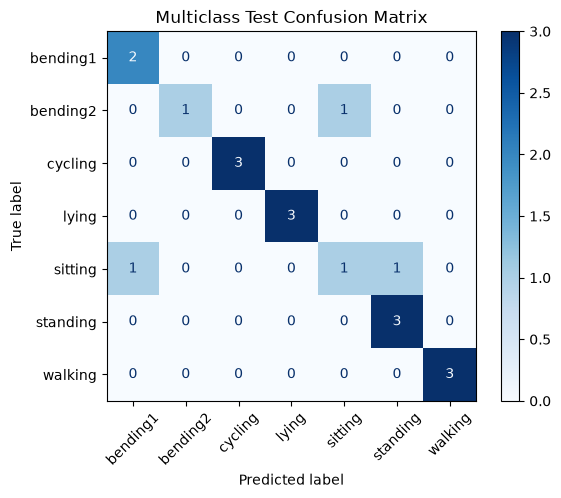

In [13]:
#multiclass confusion matrix
ConfusionMatrixDisplay.from_predictions( ytestm, multi_pred, display_labels=encoder.classes_, xticks_rotation=45, cmap="Blues")
plt.title("Multiclass Test Confusion Matrix")
plt.show()

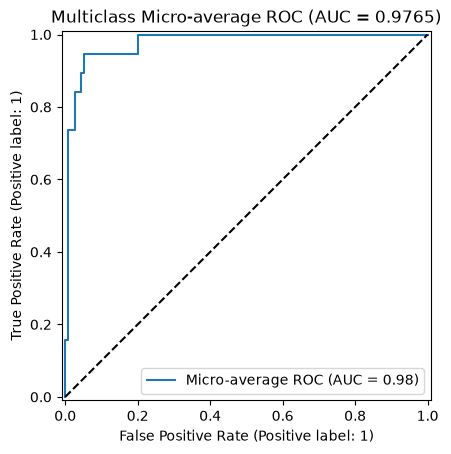

Micro-average AUC: 0.9765
Macro-average OvR AUC: 0.9779


In [14]:
# multiclass ROC and AUC
ytestb = label_binarize(ytestm,classes=np.arange(len(encoder.classes_)))
macro_auc = roc_auc_score(ytestb, multi_prob,average="macro",multi_class="ovr")
micro_auc = roc_auc_score(ytestb,multi_prob,average="micro",multi_class="ovr")
RocCurveDisplay.from_predictions(ytestb.ravel(),multi_prob.ravel(),name="Micro-average ROC")
plt.plot([0, 1], [0, 1], "k--")
plt.title(f"Multiclass Micro-average ROC (AUC = {micro_auc:.4f})")
plt.show()
print("Micro-average AUC:", round(micro_auc, 4))
print("Macro-average OvR AUC:", round(macro_auc, 4))

Understanding:

The model correctly classified 16 of 19 test instances giving 84.21% accuracy and 15.79% error. The macro-average and micro-average AUC values summarize the model’s one-vs-rest discrimination across all seven activity classes.

####   ii. Naive Bayes

In [15]:
nb_models = {"Gaussian": GaussianNB(), "Multinomial": MultinomialNB()}
nb_results = []
for l in range(1, 21):
    print(f"Testing l = {l}/20")
    X = pd.DataFrame([partlf(file, l) for activity, file in train_files])
    for name, model in nb_models.items():
        score = cross_val_score(model, X, ytrainm, cv=multi_cv, scoring="accuracy").mean()
        nb_results.append([name, l, score])
nb_results = pd.DataFrame(nb_results, columns=["Model", "l", "CV Accuracy"])
print(nb_results.pivot(index="l", columns="Model", values="CV Accuracy").round(4))
nb_summary = {}
for name, model in nb_models.items():
    rows = nb_results[nb_results["Model"] == name]
    best_row = rows.loc[rows["CV Accuracy"].idxmax()]   # first max wins ties (smallest l)
    nb_best_l = int(best_row["l"])
    nb_best_cv = best_row["CV Accuracy"]
    X_tr = pd.DataFrame([partlf(file, nb_best_l) for activity, file in train_files])
    X_te = pd.DataFrame([partlf(file, nb_best_l) for activity, file in test_files])
    model.fit(X_tr, ytrainm)
    pred = model.predict(X_te)
    acc = accuracy_score(ytestm, pred)
    nb_summary[name] = (nb_best_l, nb_best_cv, acc)
    print(f"\n{name} Naive Bayes")
    print(f"Best l = {nb_best_l}, CV accuracy = {nb_best_cv:.4f}, "f"test accuracy = {acc:.4f}, test error = {1 - acc:.4f}")
    print("Confusion matrix:\n", confusion_matrix(ytestm, pred))

Testing l = 1/20
Testing l = 2/20
Testing l = 3/20
Testing l = 4/20
Testing l = 5/20
Testing l = 6/20
Testing l = 7/20
Testing l = 8/20
Testing l = 9/20
Testing l = 10/20
Testing l = 11/20
Testing l = 12/20
Testing l = 13/20
Testing l = 14/20
Testing l = 15/20
Testing l = 16/20
Testing l = 17/20
Testing l = 18/20
Testing l = 19/20
Testing l = 20/20
Model  Gaussian  Multinomial
l                           
1        0.8562       0.8399
2        0.7966       0.8105
3        0.6944       0.7810
4        0.6650       0.7958
5        0.5637       0.7958
6        0.6953       0.7949
7        0.6797       0.8105
8        0.6936       0.7958
9        0.6078       0.7819
10       0.6364       0.7958
11       0.6503       0.7958
12       0.5637       0.7966
13       0.5956       0.7966
14       0.5515       0.7819
15       0.5212       0.7819
16       0.5507       0.8113
17       0.5523       0.7966
18       0.4788       0.7966
19       0.4926       0.7966
20       0.5376       0.7966

Gaussian N

Understanding

Gaussian Naive Bayes selected l=1, achieved 85.62% cross-validation accuracy, and obtained 89.47% test accuracy with a test error of 10.53%. Multinomial Naive Bayes also selected l=1, achieved 83.99% cross-validation accuracy, and obtained the same 89.47% test accuracy. Gaussian Naive Bayes is preferred between the two because it achieved the higher cross-validation accuracy.

####    ii. Comparison

Gaussian and Multinomial Naive Bayes both achieved 89.47% test accuracy, compared with 84.21% for L1-penalized multinomial logistic regression. Gaussian Naive Bayes is preferred because it tied for the highest test accuracy and achieved higher cross-validation accuracy than Multinomial Naive Bayes. Therefore, Gaussian Naive Bayes performed best on the provided test set.

## 3. ISLR 4.8.3

For class k, the Bayes classifier compares the following quantity:

$$
\delta_k(x)=log(\pi_k)-log(\sigma_k) -\frac{(x-\mu_k)^2}{2\sigma_k^2}
$$

Expanding the squared term gives:

$$
\delta_k(x)= -\frac{x^2}{2\sigma_k^2} +\frac{\mu_kx}{\sigma_k^2} -\frac{\mu_k^2}{2\sigma_k^2} -log(\sigma_k)+log(\pi_k)
$$

This expression contains an $x^2$ term. Since each class can have a different variance, the coefficients of $x^2$ are different and do not cancel when two classes are compared. Therefore, the Bayes classifier is quadratic rather than linear.

If all classes had the same variance, the $x^2$ terms would cancel, giving the linear decision rule used in LDA.

## 4. ISLR 4.8.7

Using Bayes' theorem, the probability of issuing a dividend is:

$$
P(D \mid X=4)=
\frac{0.8e^{-(4-10)^2/72}}
{0.8e^{-(4-10)^2/72}+0.2e^{-(4-0)^2/72}}
\approx 0.752
$$

Therefore, a company with a profit of 4% last year has approximately a 75.2% probability of issuing a dividend this year.